In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import torch


device = "cuda"

# Utils

In [2]:
def visualize_events(events, width, height, t_end, t_start):
    # 1. Extract and Move to CPU
    x = events['x'].detach().cpu().numpy().astype(int)
    y = events['y'].detach().cpu().numpy().astype(int)
    t = events['t'].detach().cpu().numpy()
    p = events['p'].detach().cpu().numpy() # Assuming p is 0 (OFF) and 1 (ON) or -1/1

    # Filter by time (optional: usually you want the last N milliseconds of the batch)
    mask = np.logical_and(t_start <= t, t <= t_end)
    x, y, p = x[mask], y[mask], p[mask]

    # 2. Create Blank Canvas (White background often looks cleaner for papers)
    # Using White Background:
    img = np.full((height, width, 3), 255, dtype=np.uint8)

    # 3. Define Colors (BGR for OpenCV, RGB for Matplotlib)
    # Standard Convention: Red = ON (+), Blue = OFF (-)
    color_on = np.array([0, 0, 255])   # Red in BGR (if using cv2) / Blue in RGB
    color_off = np.array([255, 0, 0])  # Blue in BGR / Red in RGB

    # Note: Check your polarity encoding.
    # ESIM often uses 1 for ON, 0 or -1 for OFF.
    mask_pos = (p == 1)
    mask_neg = (p == 0) | (p == -1)

    # 4. Draw Events
    # We simply set the pixel color.
    # For a 'heatmap' style where density matters, you would need accumulation,
    # but for crisp feature visualization, direct setting is usually clearer.

    if len(x) > 0:
        # Set OFF events (Blue)
        img[y[mask_neg], x[mask_neg]] = color_off

        # Set ON events (Red) - drawn second to overlay if they overlap
        img[y[mask_pos], x[mask_pos]] = color_on

    return img

# load the video

In [3]:
FPS = 90
dt = 1 / FPS

In [4]:
video_input = "high_speed_output.mp4"
cap = cv2.VideoCapture(video_input)

frames = []
frame_idx = 0

if not cap.isOpened():
    print("Couldn't open the file !")

else:
    while True:

        ret, frame = cap.read()

        if not ret:
            break

        frames.append(np.mean(frame, axis=-1))
        frame_idx += 1


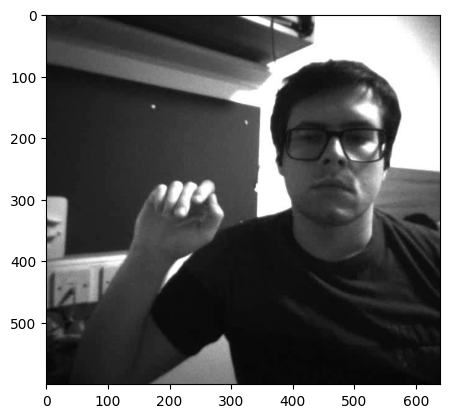

In [5]:
plt.imshow(frames[0], cmap='gray')

# save the individual frames

In [6]:
root_save = os.path.join(".", "raw_frames")

os.makedirs(root_save, exist_ok=True)

for i, frame in enumerate(frames):
    filepath = os.path.join(root_save, f"{i}.png")
    cv2.imwrite(filepath, frame)

[ WARN:0@8.230] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


# Simulate with the DVS

In [7]:
import esim_torch

contrast_thresholds_neg = 0.2
contrast_thresholds_pos = 0.2

# create and reset simulator
event_simulator = esim_torch.ESIM(
            contrast_threshold_neg=contrast_thresholds_neg,
            contrast_threshold_pos=contrast_thresholds_pos,
            refractory_period_ns=0,
        )
event_simulator.reset()

In [8]:
# prepare the input
input_frames_dvs = np.array(frames.copy())
input_images = np.log(input_frames_dvs / 255.0 + 1e-4).astype(np.float32)
timestamps_ns = (np.arange(0, len(input_images)) * dt)

input_images = torch.from_numpy(input_images).to(device, non_blocking=True)
timestamps_ns = (1e9 * timestamps_ns).astype(np.int64)
timestamps_ns_t = torch.from_numpy(timestamps_ns).to(device, non_blocking=True)

In [9]:

# reset + simulate events
events = event_simulator.forward(input_images, timestamps_ns_t)
x, y, t, p = events["x"], events["y"], events["t"], events["p"]  # GPU tensors


915


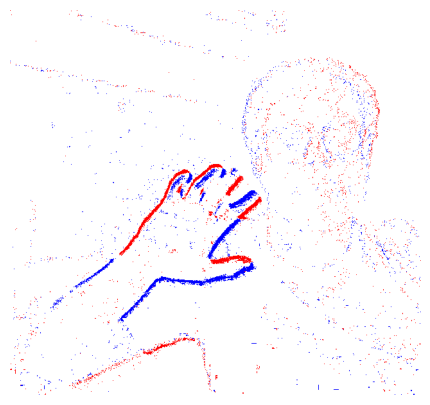

In [10]:
H, W = input_frames_dvs.shape[1], input_frames_dvs.shape[2]
print(len(input_images))

start_frame = 900
end_frame = 902
ms_period = round((end_frame - start_frame) / FPS * 1e3, 1)

# Generate the image
event_viz = visualize_events(events, width=W, height=H, t_start = int(start_frame / FPS * 1e9), t_end= int(end_frame / FPS * 1e9) ) # 30ms window

# Display
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(event_viz, cv2.COLOR_BGR2RGB)) # Convert BGR to RGB for matplotlib00000
#plt.title(f"DVS Events (Accumulated {ms_period} ms), starting_at {round(start_frame / FPS *1e3, 1)}, ending_at {round(end_frame / FPS *1e3, 1)}")
plt.savefig("events_visualized.jpg")
plt.axis('off')
plt.show()

In [11]:
cv2.imwrite("events_visualized.jpg", cv2.cvtColor(event_viz, cv2.COLOR_BGR2RGB))

True

In [12]:
import os
from tqdm import tqdm

delta_t = 2
ms_period = round((delta_t+1) / FPS * 1e3, 1)
folder = f"dvs+bins={ms_period}ms"

os.makedirs(folder, exist_ok=True)
H, W = input_frames_dvs.shape[1], input_frames_dvs.shape[2]
print(len(input_images))


for i in tqdm(range(0, len(input_images) - delta_t)):
    start_frame = i
    end_frame = i + delta_t

    # Generate the image
    event_viz = visualize_events(events, width=W, height=H, t_start = int(start_frame / FPS * 1e9), t_end= int(end_frame / FPS * 1e9) ) # 30ms window
    cv2.imwrite(os.path.join(folder, f"{i}_to_{i+delta_t}.png"), cv2.cvtColor(event_viz, cv2.COLOR_BGR2RGB))

915


100%|██████████| 913/913 [03:32<00:00,  4.30it/s]


# Simulate the Retina

In [23]:
def visualize_retina_frames(pos_tensor, neg_tensor, start_idx, end_idx, height, width):
    """
    Visualizes dense retina event frames (T, H, W) as a single Red/Blue image.
    Matches the style of the DVS visualization.
    """
    # 1. Create Blank White Canvas
    img = np.full((height, width, 3), 255, dtype=np.uint8)

    # 2. Extract window and collapse time
    # We take the logical OR across the time dimension to see if an event happened
    # in this window. (Summing is also an option if you want density).

    # Slice the tensor [Time, Height, Width]
    # Ensure we are on CPU and numpy
    p_chunk = pos_tensor[start_idx:end_idx].cpu().numpy()
    n_chunk = neg_tensor[start_idx:end_idx].cpu().numpy()

    # Collapse: if ANY frame in the window has a spike, mark it.
    pos_mask = np.any(p_chunk > 0, axis=0) # Shape: (H, W)
    neg_mask = np.any(n_chunk > 0, axis=0)

    # 3. Define Colors (BGR for OpenCV consistency with your previous code)
    color_on = np.array([0, 0, 255])   # Red
    color_off = np.array([255, 0, 0])  # Blue

    # 4. Draw
    # Draw Negative (Blue) first
    img[neg_mask] = color_off
    # Draw Positive (Red) on top
    img[pos_mask] = color_on

    return img

def visualize_heatmap(tensor_data, frame_idx, cmap_name='seismic', normalize_sym=True):
    """
    Visualizes an analog intermediate state (OPL, Voltage) as a heatmap.
    """
    # Extract specific frame
    data = tensor_data[frame_idx].cpu().numpy()

    # Normalize
    if normalize_sym:
        # For OPL (Difference of Gaussians), 0 should be gray.
        # We find the max absolute value to center the colormap at 0.
        max_val = np.max(np.abs(data)) + 1e-5
        norm_data = data / max_val # Now between -1 and 1
        # Shift to 0-1 for matplotlib colormap
        norm_data = (norm_data + 1) / 2.0
    else:
        # For Gain/Voltage (0 to Max)
        min_val = np.min(data)
        max_val = np.max(data) + 1e-5
        norm_data = (data - min_val) / (max_val - min_val)

    # Apply Colormap
    cmap = plt.get_cmap(cmap_name)
    colored_img = cmap(norm_data) # Returns RGBA float 0-1

    # Convert to RGB uint8 0-255
    img_uint8 = (colored_img[:, :, :3] * 255).astype(np.uint8)
    return img_uint8

In [24]:
H, W = frames[0].shape
T = len(frames)

In [25]:
import os
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm import tqdm
from esim_torch import SiliconRetinaVerboseFloatCUDA, SiliconRetinaFloatCUDAOnline, SiliconRetinaConfig
import torch
import torch.nn.functional as F
import math

In [18]:
# --- Configuration ---
if 'FPS' not in locals():
    FPS = 30
if 'bins' not in locals():
    bins = 3  # Number of frames to accumulate for event visualization

# Ensure output directories exist
output_root = os.path.join(".", "retina_visualization")
subfolders = ["0_Input", "1_I_C", "2_I_S", "3_I_OPL", "4_V_BIP", "5_g_A",
              "6_V_LIF_On", "7_V_LIF_Off", "8_Events", "Stitched"]

for sub in subfolders:
    os.makedirs(os.path.join(output_root, sub), exist_ok=True)

# --- Visualization Helpers ---
def norm_signed(tensor):
    """Normalize signed data (centered at 0) to 0-255 for diverging colormap."""
    data = tensor.detach().cpu().numpy()
    max_val = np.max(np.abs(data)) + 1e-6
    norm = (data / max_val + 1) / 2.0  # Map -Max..Max to 0..1
    return np.clip(norm * 255, 0, 255).astype(np.uint8)

def norm_unsigned(tensor):
    """Normalize unsigned data (0 to Max) to 0-255."""
    data = tensor.detach().cpu().numpy()
    min_val, max_val = np.min(data), np.max(data) + 1e-6
    norm = (data - min_val) / (max_val - min_val)
    return np.clip(norm * 255, 0, 255).astype(np.uint8)

def norm_unsigned_ranges(tensor, min_val, max_val):
    data = tensor.detach().cpu().numpy()
    norm = (data - min_val) / (max_val - min_val) * 255
    return np.clip(norm ,0,255).astype(np.uint8)

def apply_cmap(normed_data, cmap_name):
    """Apply matplotlib colormap to 0-255 uint8 data."""
    cmap = plt.get_cmap(cmap_name)
    colored = cmap(normed_data / 255.0)[:, :, :3] # Drop Alpha
    bgr = (colored * 255).astype(np.uint8)
    return cv2.cvtColor(bgr, cv2.COLOR_RGB2BGR)

def compute_gA(v_bip_lpf_tensor, kernel_size=31, sigma=5.0):
    """
    Approximate g_A using a Gaussian blur on V_BIP_LPF.
    """
    # 1. Create a 1D Gaussian distribution
    # Coordinate grid: [-15, -14, ..., 0, ..., 14, 15] for size 31
    coords = torch.arange(kernel_size, dtype=v_bip_lpf_tensor.dtype, device=v_bip_lpf_tensor.device)
    coords -= (kernel_size - 1) / 2.0

    g1d = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g1d /= g1d.sum()  # Normalize so sum is 1.0

    # 2. Create 2D Gaussian kernel via outer product
    # Shape: (1, 1, K, K)
    g2d = torch.outer(g1d, g1d).unsqueeze(0).unsqueeze(0)

    # 3. Prepare Input: (H, W) -> (1, 1, H, W)
    inp = v_bip_lpf_tensor.unsqueeze(0).unsqueeze(0)

    # 4. Apply Convolution
    # Padding = kernel_size // 2 to maintain the same spatial resolution
    padding = kernel_size // 2
    blurred = F.conv2d(inp, g2d, padding=padding)

    return blurred.squeeze()

def put_label(img, text):
    """Add a small text label to an image."""
    font = cv2.FONT_HERSHEY_SIMPLEX
    scale = 0.5
    color = (255, 255, 255) # White
    thickness = 1
    cv2.putText(img, text, (10, 20), font, scale, (0, 0, 0), thickness + 2) # Outline
    cv2.putText(img, text, (10, 20), font, scale, color, thickness)         # Text
    return img

def visualize_binned_events(pos_list, neg_list, bins, height, width):
    """
    Accumulates the last 'bins' frames from the lists and creates a BGR image.
    """
    img = np.full((height, width, 3), 255, dtype=np.uint8) # White background

    # Get the last N frames
    start_idx = max(0, len(pos_list) - bins)

    # Stack simple python list into tensor for easy slicing
    # Note: iterating a short list is fast enough
    p_chunk = torch.stack(pos_list[start_idx:])
    n_chunk = torch.stack(neg_list[start_idx:])

    # Collapse time (Logical OR)
    pos_mask = (p_chunk.sum(dim=0) > 0).cpu().numpy()
    neg_mask = (n_chunk.sum(dim=0) > 0).cpu().numpy()

    # Colors (BGR)
    color_on = np.array([0, 0, 255])   # Red
    color_off = np.array([255, 0, 0])  # Blue

    img[neg_mask] = color_off
    img[pos_mask] = color_on

    return img

print("STARTED")
kernel2_sigma = 2.0
kernel2_size = 9
# --- Model Setup ---
cfg = SiliconRetinaConfig(H = H, W = W,
                          alpha1=0.5, alpha2=0.5, V_BIP_LPF_alpha=0.5,
                          lambda_OPL=3.0, G_A_zero=0.5, lambda_A=2.0,
                          p1=0.6, I_bias_on=0.01, I_bias_off=0.01,
                          p2=1.0, p3=0.2,
                          U_rest_on=-0.05, U_rest_off=-0.05,
                          U_th_on=0.02, U_th_off=0.02,
                          U_reset_on=0.04, U_reset_off=0.04,
                          HPF1_mode=1, HPF1_param=0.5,
                          HPF2_mode=1, HPF2_param=0.5,
                          blur1_mode=0, blur2_mode=0,
                          kernel1_type=1, kernel2_type=1,
                          kernel1_size=9, kernel2_size=kernel2_size,
                          kernel1_sigma=2.0, kernel2_sigma=kernel2_sigma,
                          q_feedback_mode = 1)



model = SiliconRetinaFloatCUDAOnline(silicon_retina_config=cfg)
model.reset()

print(f"Processing {T} frames...")

positive, negative = [], []
video_writer = None



for t in tqdm(range(1, T + 1, 1)):

    # 1. Run Model
    frame_tensor = (frames[t-1][None] / 255.).astype(np.float32)
    input_t = torch.Tensor(frame_tensor).to(device)
    p, n = model(input_t, t)

    # Append new events to list
    positive.append((n.clone()[0]))
    negative.append((p.clone()[0]))

    # 2. Extract Intermediate Tensors
    raw_input = norm_unsigned(input_t.squeeze())

    t_I_C   = model.HPF1[t%2]
    t_I_S   = model.LPF2[t%2]
    t_I_OPL = model.I_OPL[t%2]
    t_V_BIP = model.V_BIP[t%2]
    t_V_BIP_LPF = model.V_BIP_LPF[t%2]
    t_g_A   = compute_gA(t_V_BIP_LPF, kernel_size=kernel2_size, sigma=kernel2_sigma)
    t_V_LIF_on  = model.V_LIF_on[t%2]
    t_V_LIF_off = model.V_LIF_off[t%2]

    # 3. Generate Images
    img_input = cv2.cvtColor(raw_input, cv2.COLOR_GRAY2BGR)
    img_I_C = apply_cmap(norm_unsigned(t_I_C), 'gray')
    img_I_S = apply_cmap(norm_unsigned(t_I_S), 'gray')
    img_I_OPL = apply_cmap(norm_signed(t_I_OPL), 'seismic')
    img_V_BIP = apply_cmap(norm_unsigned(t_V_BIP), 'magma')
    img_g_A = apply_cmap(norm_unsigned_ranges(t_g_A, 0, 1.0), 'gray')
    img_LIF_on  = apply_cmap(norm_unsigned_ranges(t_V_LIF_on, -0.05, 0.05), 'inferno')
    img_LIF_off = apply_cmap(norm_unsigned_ranges(t_V_LIF_off, -0.05, 0.05), 'inferno')

    # 4. Generate Event Image (Looking back 'bins' frames)
    img_events = visualize_binned_events(negative,positive, bins, H, W)

    # 5. Save Individual Files
    filename = f"frame_{t:04d}.png"
    cv2.imwrite(os.path.join(output_root, "0_Input", filename), img_input)
    cv2.imwrite(os.path.join(output_root, "1_I_C", filename), img_I_C)
    cv2.imwrite(os.path.join(output_root, "2_I_S", filename), img_I_S)
    cv2.imwrite(os.path.join(output_root, "3_I_OPL", filename), img_I_OPL)
    cv2.imwrite(os.path.join(output_root, "4_V_BIP", filename), img_V_BIP)
    cv2.imwrite(os.path.join(output_root, "5_g_A", filename), img_g_A)
    cv2.imwrite(os.path.join(output_root, "6_V_LIF_On", filename), img_LIF_on)
    cv2.imwrite(os.path.join(output_root, "7_V_LIF_Off", filename), img_LIF_off)
    cv2.imwrite(os.path.join(output_root, "8_Events", filename), img_events)

    # 6. Create Stitched Grid (3x3)
    # Row 1: Input | I_C | I_S
    row1 = np.hstack([
        put_label(img_input.copy(), "Input"),
        put_label(img_I_C.copy(), "I_C (Center)"),
        put_label(img_I_S.copy(), "I_S (Surround)"),
    ])

    # Row 2: I_OPL | V_BIP | g_A
    row2 = np.hstack([
        put_label(img_I_OPL.copy(), "I_OPL (Diff)"),
        put_label(img_V_BIP.copy(), "V_BIP (Voltage)"),
        put_label(img_g_A.copy(), "g_A (Gain)"),
    ])

    # Row 3: LIF_ON | LIF_OFF | Events
    row3 = np.hstack([
        put_label(img_LIF_on.copy(), "LIF (ON)"),
        put_label(img_LIF_off.copy(), "LIF (OFF)"),
        put_label(img_events.copy(), f"Events (Acc {bins})")
    ])

    stitched = np.vstack([row1, row2, row3])

    # Save Stitched Frame
    cv2.imwrite(os.path.join(output_root, "Stitched", filename), stitched)

    # 7. Write to Video
    if video_writer is None:
        vid_h, vid_w = stitched.shape[:2]
        video_path = os.path.join(output_root, "retina_output_video.mp4")
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        video_writer = cv2.VideoWriter(video_path, fourcc, 30, (vid_w, vid_h))
        print(f"Initialized video writer: {video_path}")

    video_writer.write(stitched)

# Cleanup
if video_writer is not None:
    video_writer.release()

print("Visualization complete. Video saved.")

STARTED
Processing 915 frames...


  0%|          | 1/915 [00:00<02:29,  6.11it/s]

Initialized video writer: ./retina_visualization/retina_output_video.mp4


100%|██████████| 915/915 [02:34<00:00,  5.93it/s]

Visualization complete. Video saved.


# Better Plots ?

In [37]:
def norm_signed(tensor, p=99.0):
    """Normalize signed data symmetrically using percentile clipping."""
    data = tensor.detach().cpu().numpy()
    
    # Use percentile of absolute values to keep the 0-center perfectly symmetric
    abs_data = np.abs(data)
    max_val = float(np.percentile(abs_data, p)) + 1e-6
    
    # Clip extreme outliers before normalization
    clipped_data = np.clip(data, -max_val, max_val)
    
    # Map [-max_val, max_val] to [0, 1]
    norm = (clipped_data / max_val + 1) / 2.0  
    return (norm * 255).astype(np.uint8), -max_val, max_val

def norm_unsigned(tensor, p_high=99.0, p_low=1.0):
    """Normalize unsigned data using upper and lower percentile clipping."""
    data = tensor.detach().cpu().numpy()
    
    min_val = float(np.percentile(data, p_low))
    max_val = float(np.percentile(data, p_high)) + 1e-6
    
    # Clip extreme outliers
    clipped_data = np.clip(data, min_val, max_val)
    
    # Map [min_val, max_val] to [0, 1]
    norm = (clipped_data - min_val) / (max_val - min_val)
    return (norm * 255).astype(np.uint8), min_val, max_val

def norm_unsigned_ranges(tensor, min_val, max_val):
    """Normalize unsigned data using fixed bounds."""
    data = tensor.detach().cpu().numpy()
    norm = (data - min_val) / (max_val - min_val)
    return np.clip(norm * 255, 0, 255).astype(np.uint8), min_val, max_val

def apply_cmap(normed_data, cmap_name):
    """Apply matplotlib colormap to 0-255 uint8 data."""
    cmap = plt.get_cmap(cmap_name)
    colored = cmap(normed_data / 255.0)[:, :, :3]
    bgr = (colored * 255).astype(np.uint8)
    return cv2.cvtColor(bgr, cv2.COLOR_RGB2BGR)

def add_colorbar(img, cmap_name, min_val, max_val):
    """Generates a matplotlib-style colorbar that scales dynamically with image width."""
    h, w = img.shape[:2]
    
    # Dynamically scale sizes based on image width (baseline of 300px)
    scale = max(1.0, w / 300.0)
    
    cbar_thickness = int(12 * scale)
    margin_top = int(8 * scale)
    margin_side = int(15 * scale)
    
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.4 * scale
    thickness = max(1, int(1 * scale))
    
    # Calculate exact text height required
    text_size, baseline = cv2.getTextSize("0.000", font, font_scale, thickness)
    text_height = text_size[1] + baseline + int(8 * scale)
    
    total_bottom_height = margin_top + cbar_thickness + text_height
    
    # Create a white canvas for the bottom section
    bottom_panel = np.full((total_bottom_height, w, 3), 255, dtype=np.uint8)
    
    # Calculate gradient strip width
    strip_w = w - 2 * margin_side
    if strip_w <= 0: 
        return img 
    
    # Generate 1D gradient and expand to 2D strip
    gradient = np.linspace(0, 1, strip_w)
    gradient = np.tile(gradient, (cbar_thickness, 1))
    
    # Apply colormap
    cmap = plt.get_cmap(cmap_name)
    cbar_rgb = (cmap(gradient)[:, :, :3] * 255).astype(np.uint8)
    cbar_bgr = cv2.cvtColor(cbar_rgb, cv2.COLOR_RGB2BGR)

    # Add a 1px black border around the gradient strip
    cbar_bordered = cv2.copyMakeBorder(cbar_bgr, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=(0, 0, 0))
    bh, bw = cbar_bordered.shape[:2]
    
    # Place the bordered strip onto the white canvas
    y_offset = margin_top
    x_offset = margin_side - 1 
    bottom_panel[y_offset:y_offset+bh, x_offset:x_offset+bw] = cbar_bordered

    def draw_text(text, position):
        t_size, _ = cv2.getTextSize(text, font, font_scale, thickness)
        y = y_offset + bh + t_size[1] + int(4 * scale)
        
        if position == 'left':
            x = x_offset
        elif position == 'center':
            x = x_offset + bw // 2 - t_size[0] // 2
        else: 
            x = x_offset + bw - t_size[0]
            
        cv2.putText(bottom_panel, text, (x, y), font, font_scale, (0, 0, 0), thickness, cv2.LINE_AA)

    # Draw Min, Mid, Max values
    draw_text(f"{min_val:.3f}", 'left')
    draw_text(f"{(min_val+max_val)/2:.3f}", 'center')
    draw_text(f"{max_val:.3f}", 'right')

    return np.vstack([img, bottom_panel])

def add_blank_strip(img):
    """Adds a blank white strip matching the dynamic colorbar dimensions."""
    h, w = img.shape[:2]
    
    scale = max(1.0, w / 300.0)
    cbar_thickness = int(12 * scale)
    margin_top = int(8 * scale)
    
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.4 * scale
    thickness = max(1, int(1 * scale))
    
    text_size, baseline = cv2.getTextSize("0.000", font, font_scale, thickness)
    text_height = text_size[1] + baseline + int(8 * scale)
    
    total_bottom_height = margin_top + cbar_thickness + text_height
    strip = np.full((total_bottom_height, w, 3), 255, dtype=np.uint8)
    
    return np.vstack([img, strip])

In [39]:
# --- Configuration ---
if 'FPS' not in locals():
    FPS = 30
if 'bins' not in locals():
    bins = 3  # Number of frames to accumulate for event visualization

# Ensure output directories exist
output_root = os.path.join(".", "retina_visualization")
subfolders = ["0_Input", "1_I_C", "2_I_S", "3_I_OPL", "4_V_BIP", "5_g_A",
              "6_V_LIF_On", "7_V_LIF_Off", "8_Events", "Stitched"]

for sub in subfolders:
    os.makedirs(os.path.join(output_root, sub), exist_ok=True)

model = SiliconRetinaFloatCUDAOnline(silicon_retina_config=cfg)
model.reset()

print(f"Processing {T} frames...")

positive, negative = [], []
video_writer = None



for t in tqdm(range(1, T + 1, 1)):

    # 1. Run Model
    frame_tensor = (frames[t-1][None] / 255.).astype(np.float32)
    input_t = torch.Tensor(frame_tensor).to(device)
    p, n = model(input_t, t)

    # Append new events to list
    positive.append((n.clone()[0]))
    negative.append((p.clone()[0]))

    # 2. Extract Intermediate Tensors & Compute Bounds
    raw_data, in_min, in_max = norm_unsigned(input_t.squeeze())
    raw_input = raw_data
    
    t_I_C   = model.HPF1[t%2]
    t_I_S   = model.LPF2[t%2]
    t_I_OPL = model.I_OPL[t%2]
    t_V_BIP = model.V_BIP[t%2]
    t_V_BIP_LPF = model.V_BIP_LPF[t%2]
    t_g_A   = compute_gA(t_V_BIP_LPF, kernel_size=kernel2_size, sigma=kernel2_sigma)
    t_V_LIF_on  = model.V_LIF_on[t%2]
    t_V_LIF_off = model.V_LIF_off[t%2]

    # Normalize and get bounds
    norm_I_C, min_I_C, max_I_C = norm_unsigned(t_I_C)
    norm_I_S, min_I_S, max_I_S = norm_unsigned(t_I_S)
    norm_I_OPL, min_I_OPL, max_I_OPL = norm_signed(t_I_OPL)
    norm_V_BIP, min_V_BIP, max_V_BIP = norm_unsigned(t_V_BIP)
    
    # Fixed ranges
    norm_g_A, min_g_A, max_g_A = norm_unsigned(t_g_A) #norm_unsigned_ranges(t_g_A, 0.0, 1.0)
    norm_LIF_on, min_LIF_on, max_LIF_on = norm_signed(t_V_LIF_on, p=100.) # norm_unsigned_ranges(t_V_LIF_on, -0.05, 0.05)
    norm_LIF_off, min_LIF_off, max_LIF_off = norm_signed(t_V_LIF_off, p=100.) #norm_unsigned_ranges(t_V_LIF_off, -0.05, 0.05)

    # 3. Generate Images & Add Colorbars
    img_input = cv2.cvtColor(raw_input, cv2.COLOR_GRAY2BGR)
    img_input = add_blank_strip(img_input) # Pad to keep heights consistent

    img_I_C = add_colorbar(apply_cmap(norm_I_C, 'gray'), 'gray', min_I_C, max_I_C)
    img_I_S = add_colorbar(apply_cmap(norm_I_S, 'gray'), 'gray', min_I_S, max_I_S)
    
    img_I_OPL = add_colorbar(apply_cmap(norm_I_OPL, 'gray'), 'gray', min_I_OPL, max_I_OPL)
    img_V_BIP = add_colorbar(apply_cmap(norm_V_BIP, 'gray'), 'gray', min_V_BIP, max_V_BIP)
    img_g_A   = add_colorbar(apply_cmap(norm_g_A, 'gray'), 'gray', min_g_A, max_g_A)
    
    img_LIF_on  = add_colorbar(apply_cmap(norm_LIF_on, 'seismic'), 'seismic', min_LIF_on, max_LIF_on)
    img_LIF_off = add_colorbar(apply_cmap(norm_LIF_off, 'seismic'), 'seismic', min_LIF_off, max_LIF_off)

    # 4. Generate Event Image & Pad
    img_events = visualize_binned_events(negative, positive, bins, H, W)
    img_events = add_blank_strip(img_events)
    
    
    # 5. Save Individual Files
    filename = f"frame_{t:04d}.png"
    cv2.imwrite(os.path.join(output_root, "0_Input", filename), img_input)
    cv2.imwrite(os.path.join(output_root, "1_I_C", filename), img_I_C)
    cv2.imwrite(os.path.join(output_root, "2_I_S", filename), img_I_S)
    cv2.imwrite(os.path.join(output_root, "3_I_OPL", filename), img_I_OPL)
    cv2.imwrite(os.path.join(output_root, "4_V_BIP", filename), img_V_BIP)
    cv2.imwrite(os.path.join(output_root, "5_g_A", filename), img_g_A)
    cv2.imwrite(os.path.join(output_root, "6_V_LIF_On", filename), img_LIF_on)
    cv2.imwrite(os.path.join(output_root, "7_V_LIF_Off", filename), img_LIF_off)
    cv2.imwrite(os.path.join(output_root, "8_Events", filename), img_events)

    # 6. Create Stitched Grid (3x3)
    # Row 1: Input | I_C | I_S
    row1 = np.hstack([
        put_label(img_input.copy(), "Input"),
        put_label(img_I_C.copy(), "I_C (Center)"),
        put_label(img_I_S.copy(), "I_S (Surround)"),
    ])

    # Row 2: I_OPL | V_BIP | g_A
    row2 = np.hstack([
        put_label(img_I_OPL.copy(), "I_OPL (Diff)"),
        put_label(img_V_BIP.copy(), "V_BIP (Voltage)"),
        put_label(img_g_A.copy(), "g_A (Gain)"),
    ])

    # Row 3: LIF_ON | LIF_OFF | Events
    row3 = np.hstack([
        put_label(img_LIF_on.copy(), "LIF (ON)"),
        put_label(img_LIF_off.copy(), "LIF (OFF)"),
        put_label(img_events.copy(), f"Events (Acc {bins})")
    ])

    stitched = np.vstack([row1, row2, row3])

    # Save Stitched Frame
    cv2.imwrite(os.path.join(output_root, "Stitched", filename), stitched)

    # 7. Write to Video
    if video_writer is None:
        vid_h, vid_w = stitched.shape[:2]
        video_path = os.path.join(output_root, "retina_output_video.mp4")
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        video_writer = cv2.VideoWriter(video_path, fourcc, 30, (vid_w, vid_h))
        print(f"Initialized video writer: {video_path}")

    video_writer.write(stitched)

# Cleanup
if video_writer is not None:
    video_writer.release()

print("Visualization complete. Video saved.")

Processing 915 frames...


  0%|          | 2/915 [00:00<03:07,  4.87it/s]

Initialized video writer: ./retina_visualization/retina_output_video.mp4


100%|██████████| 915/915 [03:06<00:00,  4.91it/s]

Visualization complete. Video saved.
